## **Exercise: Algorithm Chain**

Anda bekerja sebagai data scientist di perusahaan asuransi. Anda diminta untuk memprediksi apakah seorang calon nasabah akan mengajukan klaim ketika dia memiliki asuransi atau tidak. 

- Dataset: Car_Insurance_Claim.csv
- Target: 'OUTCOME'

In [227]:
# !pip install category_encoders

In [228]:
import numpy as np
import pandas as pd
import seaborn as sns 
import matplotlib.pyplot as plt

# train test split
from sklearn.model_selection import train_test_split

# menyatukan beberapa tahap preprocessing atau fungsi lainnya
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

# encoder dan scaler
from sklearn.preprocessing import OneHotEncoder
from category_encoders import BinaryEncoder, OrdinalEncoder
from sklearn.preprocessing import RobustScaler, MinMaxScaler, StandardScaler
from sklearn.experimental import enable_iterative_imputer
from sklearn.impute import SimpleImputer, IterativeImputer


# algoritma ML
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier, plot_tree

# cross validation untuk menentukan algoritma terbaik
from sklearn.model_selection import cross_val_score, StratifiedKFold

# metrics untuk regresi
from sklearn.metrics import f1_score, classification_report, confusion_matrix, precision_recall_curve, PrecisionRecallDisplay, roc_auc_score, roc_curve

## Load Dataset

In [229]:
df = pd.read_csv('Car_Insurance_Claim.csv')
df.head()

,ID,AGE,GENDER,RACE,DRIVING_EXPERIENCE,EDUCATION,INCOME,CREDIT_SCORE,VEHICLE_OWNERSHIP,VEHICLE_YEAR,MARRIED,CHILDREN,POSTAL_CODE,ANNUAL_MILEAGE,VEHICLE_TYPE,SPEEDING_VIOLATIONS,DUIS,PAST_ACCIDENTS,OUTCOME
0,569520,65+,female,majority,0-9y,high school,upper class,0.629027,1.0,after 2015,0.0,1.0,10238,12000.0,sedan,0,0,0,0.0
1,750365,16-25,male,majority,0-9y,none,poverty,0.357757,0.0,before 2015,0.0,0.0,10238,16000.0,sedan,0,0,0,1.0
2,199901,16-25,female,majority,0-9y,high school,working class,0.493146,1.0,before 2015,0.0,0.0,10238,11000.0,sedan,0,0,0,0.0
3,478866,16-25,male,majority,0-9y,university,working class,0.206013,1.0,before 2015,0.0,1.0,32765,11000.0,sedan,0,0,0,0.0
4,731664,26-39,male,majority,10-19y,none,working class,0.388366,1.0,before 2015,0.0,0.0,32765,12000.0,sedan,2,0,1,1.0


In [230]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 19 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   ID                   10000 non-null  int64  
 1   AGE                  10000 non-null  object 
 2   GENDER               10000 non-null  object 
 3   RACE                 10000 non-null  object 
 4   DRIVING_EXPERIENCE   10000 non-null  object 
 5   EDUCATION            10000 non-null  object 
 6   INCOME               10000 non-null  object 
 7   CREDIT_SCORE         9018 non-null   float64
 8   VEHICLE_OWNERSHIP    10000 non-null  float64
 9   VEHICLE_YEAR         10000 non-null  object 
 10  MARRIED              10000 non-null  float64
 11  CHILDREN             10000 non-null  float64
 12  POSTAL_CODE          10000 non-null  int64  
 13  ANNUAL_MILEAGE       9043 non-null   float64
 14  VEHICLE_TYPE         10000 non-null  object 
 15  SPEEDING_VIOLATIONS  10000 non-null  

In [231]:
df.describe()

,ID,CREDIT_SCORE,VEHICLE_OWNERSHIP,MARRIED,CHILDREN,POSTAL_CODE,ANNUAL_MILEAGE,SPEEDING_VIOLATIONS,DUIS,PAST_ACCIDENTS,OUTCOME
count,10000.000000,9018.000000,10000.000000,10000.000000,10000.000000,10000.000000,9043.000000,10000.000000,10000.00000,10000.000000,10000.000000
mean,500521.906800,0.515813,0.697000,0.498200,0.688800,19864.548400,11697.003207,1.482900,0.23920,1.056300,0.313300
std,290030.768758,0.137688,0.459578,0.500022,0.463008,18915.613855,2818.434528,2.241966,0.55499,1.652454,0.463858
min,101.000000,0.053358,0.000000,0.000000,0.000000,10238.000000,2000.000000,0.000000,0.00000,0.000000,0.000000
25%,249638.500000,0.417191,0.000000,0.000000,0.000000,10238.000000,10000.000000,0.000000,0.00000,0.000000,0.000000
50%,501777.000000,0.525033,1.000000,0.000000,1.000000,10238.000000,12000.000000,0.000000,0.00000,0.000000,0.000000
75%,753974.500000,0.618312,1.000000,1.000000,1.000000,32765.000000,14000.000000,2.000000,0.00000,2.000000,1.000000
max,999976.000000,0.960819,1.000000,1.000000,1.000000,92101.000000,22000.000000,22.000000,6.00000,15.000000,1.000000


In [232]:
df['POSTAL_CODE'].value_counts()

# sebaiknya diencoding

POSTAL_CODE
10238    6940
32765    2456
92101     484
21217     120
Name: count, dtype: int64

In [233]:
df.describe(include='object')

,AGE,GENDER,RACE,DRIVING_EXPERIENCE,EDUCATION,INCOME,VEHICLE_YEAR,VEHICLE_TYPE
count,10000,10000,10000,10000,10000,10000,10000,10000
unique,4,2,2,4,3,4,2,2
top,26-39,female,majority,0-9y,high school,upper class,before 2015,sedan
freq,3063,5010,9012,3530,4157,4336,6967,9523


## EDA

In [234]:
# unique values in categorical columns

for i in df.describe(include='object').columns:
    print(i, '\n', df[i].unique(), '\n')

AGE 
 ['65+' '16-25' '26-39' '40-64'] 

GENDER 
 ['female' 'male'] 

RACE 
 ['majority' 'minority'] 

DRIVING_EXPERIENCE 
 ['0-9y' '10-19y' '20-29y' '30y+'] 

EDUCATION 
 ['high school' 'none' 'university'] 

INCOME 
 ['upper class' 'poverty' 'working class' 'middle class'] 

VEHICLE_YEAR 
 ['after 2015' 'before 2015'] 

VEHICLE_TYPE 
 ['sedan' 'sports car'] 



<Axes: >

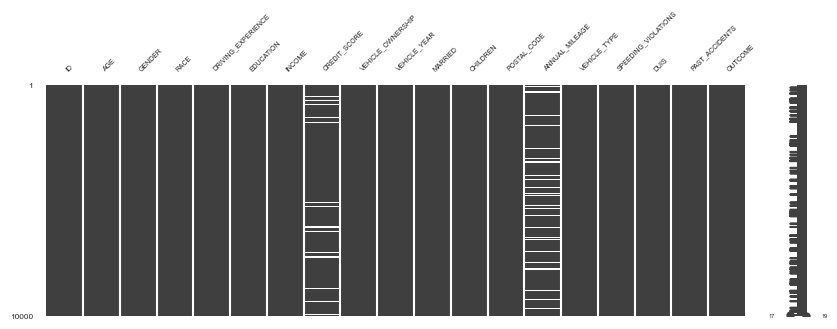

In [235]:
import missingno as msn
msn.matrix(df,figsize=(10,3),fontsize=5)

In [236]:
# missing values

df.isna().sum()

ID                       0
AGE                      0
GENDER                   0
RACE                     0
DRIVING_EXPERIENCE       0
EDUCATION                0
INCOME                   0
CREDIT_SCORE           982
VEHICLE_OWNERSHIP        0
VEHICLE_YEAR             0
MARRIED                  0
CHILDREN                 0
POSTAL_CODE              0
ANNUAL_MILEAGE         957
VEHICLE_TYPE             0
SPEEDING_VIOLATIONS      0
DUIS                     0
PAST_ACCIDENTS           0
OUTCOME                  0
dtype: int64

In [237]:
# check data nullity, unique value
pd.set_option('display.max_colwidth', None)

pd.DataFrame({
    'feature':df.columns.values,
    'data_type':df.dtypes.values,
    'null':df.isna().mean().values * 100,
    'negative':[True if df[i].dtype == int and (df[i] < 0).any() else False for i in df.columns],
    'n_unique':df.nunique().values,
    'sample_unique':[df[i].unique() for i in df.columns]
})

,feature,data_type,null,negative,n_unique,sample_unique
0,ID,int64,0.00,False,10000,"[569520, 750365, 199901, 478866, 731664, 877557, 930134, 461006, 68366, 445911, 275820, 521399, 429728, 569640, 980181, 906223, 517747, 24851, 104086, 240658, 484399, 912828, 892754, 217, 633896, 193110, 98515, 165623, 493590, 389792, 642614, 951465, 496987, 732437, 146897, 316173, 9013, 511757, 429947, 485660, 80496, 478336, 10843, 397446, 101678, 231661, 173782, 921097, 98839, 105372, 888828, 37454, 370044, 768282, 738729, 437535, 329536, 328531, 123941, 131881, 839572, 171578, 589757, 336859, 788111, 407453, 367026, 334687, 623367, 688440, 547974, 989064, 422816, 307408, 675898, 480452, 93199, 125802, 616663, 423497, 492837, 422563, 185231, 949152, 859453, 466578, 998214, 828462, 511837, 554995, 680717, 978021, 509815, 6676, 362280, 883018, 889355, 198273, 197763, 55670, ...]"
1,AGE,object,0.00,False,4,"[65+, 16-25, 26-39, 40-64]"
2,GENDER,object,0.00,False,2,"[female, male]"
3,RACE,object,0.00,False,2,"[majority, minority]"
4,DRIVING_EXPERIENCE,object,0.00,False,4,"[0-9y, 10-19y, 20-29y, 30y+]"
5,EDUCATION,object,0.00,False,3,"[high school, none, university]"
6,INCOME,object,0.00,False,4,"[upper class, poverty, working class, middle class]"
7,CREDIT_SCORE,float64,9.82,False,9018,"[0.629027313918201, 0.3577571170184627, 0.4931457852181982, 0.2060128507324556, 0.3883658881572184, 0.6191273725847388, 0.4929435502195342, 0.468689297434465, 0.5218149362971065, 0.5615310319383646, 0.6203612640126029, 0.7298308815593941, 0.6370447435902447, 0.59125997174597, 0.4615679630439447, 0.7627979410816134, 0.7961748462456987, nan, 0.6805942795073384, 0.4177139816231188, 0.4095135306516067, 0.5532600531952381, 0.3309502618581893, 0.5006306604427161, 0.5519701813636283, 0.6269960497386653, 0.2947974807719967, 0.5519504952618395, 0.649820471216227, 0.5218044346397632, 0.7012683240604196, 0.1712440288213211, 0.3184419972124171, 0.6046842696715551, 0.5049948526440377, 0.6251466352816216, 0.5781305873212035, 0.7054542902137054, 0.6595254905875941, 0.5873836120460223, 0.4064824253974476, 0.2857471319596469, 0.5022849652731057, 0.6256257210210231, 0.3931531299744003, 0.5039497598168121, 0.6586274302571438, 0.5241464657501199, 0.5531007570628673, 0.4475509489142775, 0.5107331365064207, 0.4613735917269193, 0.3875569443647317, 0.5701572256616224, 0.5501250875743224, 0.4529442316093683, 0.5352743096602144, 0.6147359485632915, 0.4544471564329259, 0.6137409183819416, 0.5326613280250595, 0.4277285143019345, 0.6859457213719147, 0.6936124267187082, 0.5979905963582334, 0.3308186664986927, 0.5083042183803546, 0.7641329165005233, 0.4775169603837716, 0.6812332078486962, 0.4671555457007022, 0.3941632454999797, 0.6610607322734078, 0.6651879748430346, 0.560770206632082, 0.7454327103696547, 0.53257435224505, 0.5267473391434415, 0.4124517461654282, 0.3871071449018297, 0.5499938678343249, 0.5853420947575604, 0.5987396054343311, 0.6026557000791793, 0.5114570584803535, 0.5586591735288894, 0.6284070137170304, 0.5057903732571783, 0.7268184180645275, 0.6904423335733175, 0.4796771646619314, 0.4405592041968235, 0.634052597196068, 0.4574695879943666, 0.3086490182004943, 0.2458351852340737, 0.3056465190413162, 0.7440140862681482, 0.6704645467899408, 0.6830407984824192, ...]"
8,VEHICLE_OWNERSHIP,float64,0.00,False,2,"[1.0, 0.0]"
9,VEHICLE_YEAR,object,0.00,False,2,"[after 2015, before 2015]"


In [238]:
df[['CREDIT_SCORE','ANNUAL_MILEAGE','SPEEDING_VIOLATIONS','DUIS','PAST_ACCIDENTS']].corr()

,CREDIT_SCORE,ANNUAL_MILEAGE,SPEEDING_VIOLATIONS,DUIS,PAST_ACCIDENTS
CREDIT_SCORE,1.000000,-0.174453,0.204542,0.127366,0.180978
ANNUAL_MILEAGE,-0.174453,1.000000,-0.323547,-0.116598,-0.195217
SPEEDING_VIOLATIONS,0.204542,-0.323547,1.000000,0.359838,0.443074
DUIS,0.127366,-0.116598,0.359838,1.000000,0.259359
PAST_ACCIDENTS,0.180978,-0.195217,0.443074,0.259359,1.000000


<Axes: >

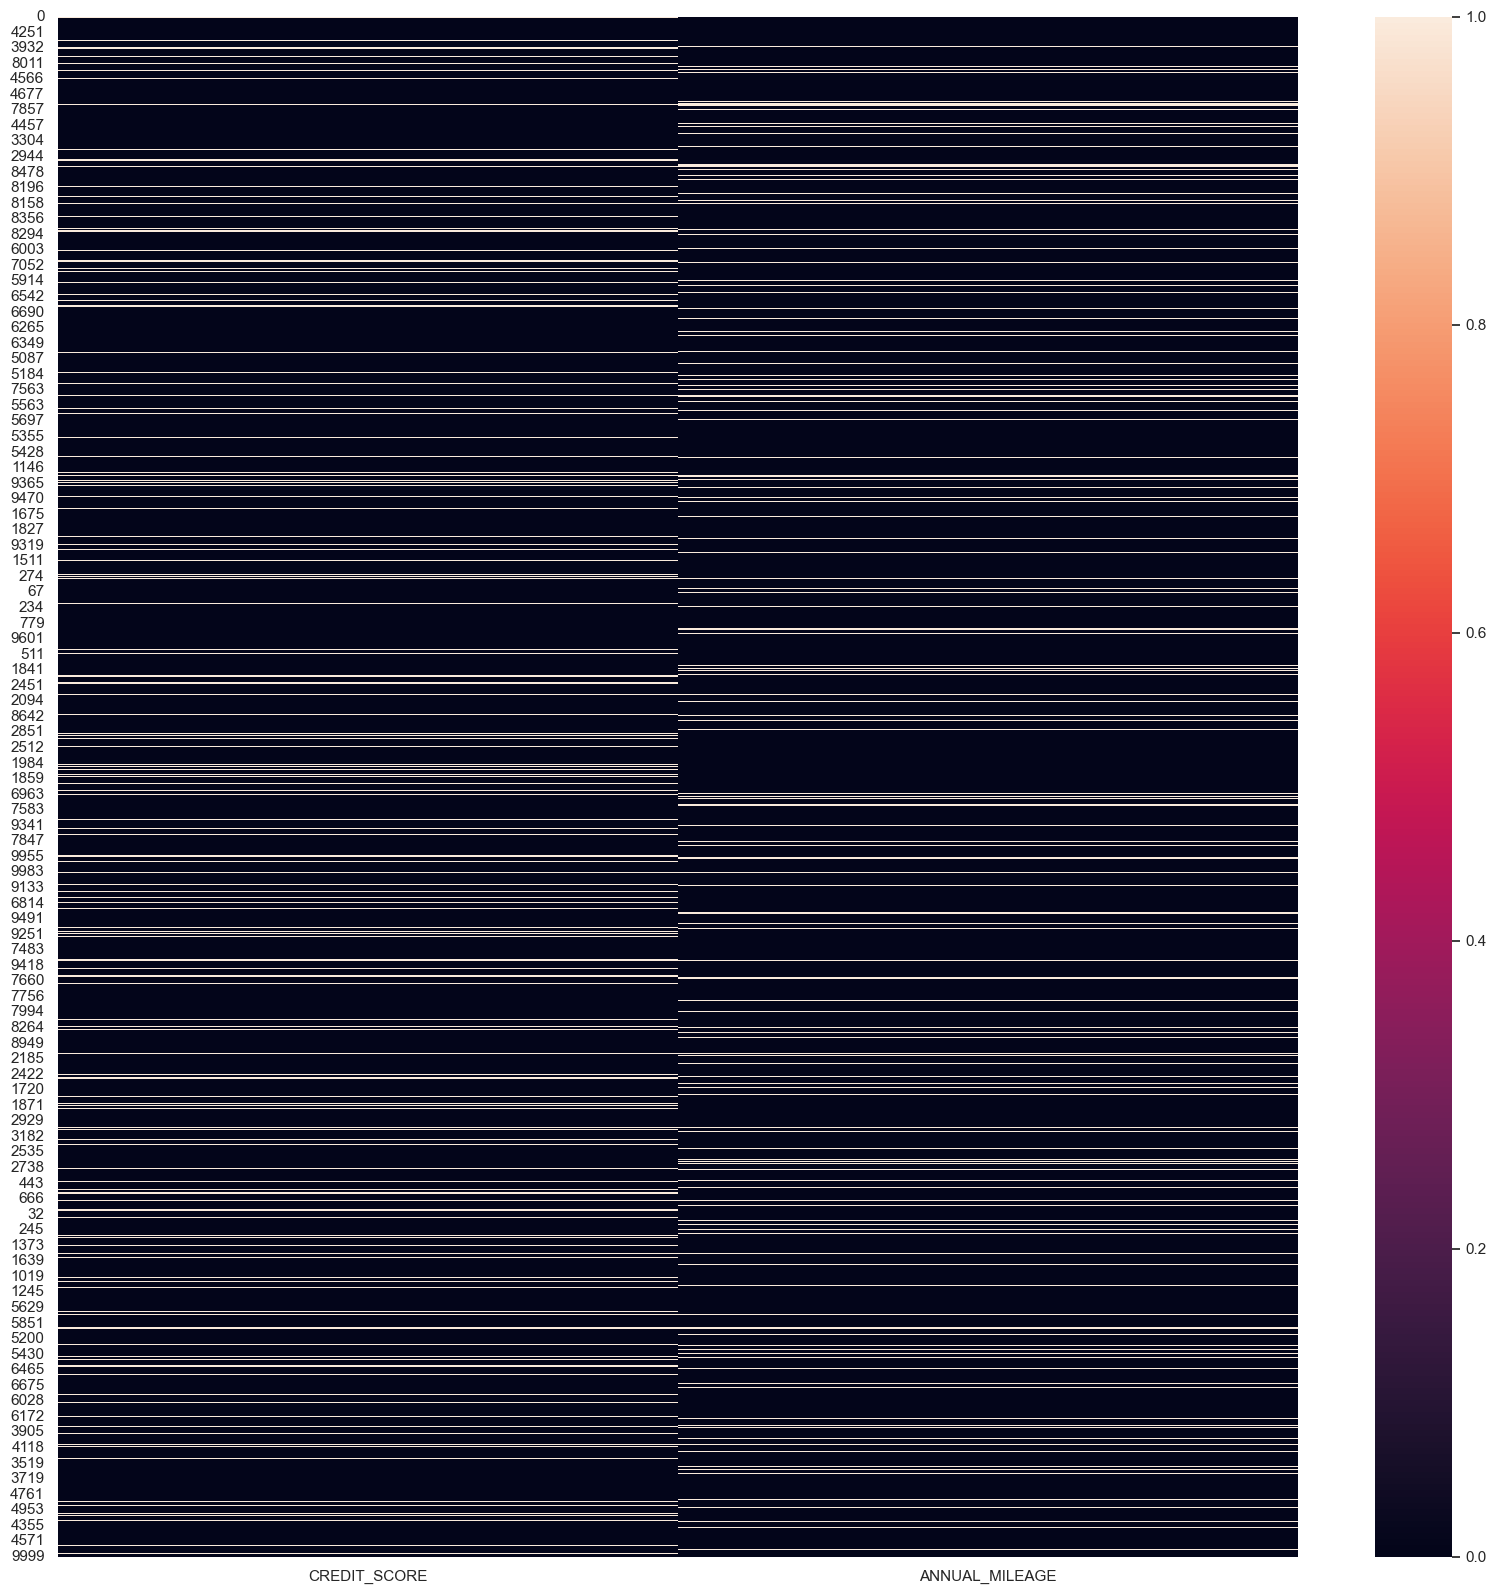

In [239]:
plt.figure(figsize = (20,20))
sns.heatmap(df.sort_values('MARRIED')[['CREDIT_SCORE','ANNUAL_MILEAGE']].isna())

In [240]:
# df['MARRIED'].value_counts()
df['MARRIED'].value_counts()

MARRIED
0.0    5018
1.0    4982
Name: count, dtype: int64

In [241]:
df['MARRIED'].sort_values()

0       0.0
4151    0.0
4150    0.0
4149    0.0
7958    0.0
       ... 
4485    1.0
4484    1.0
4483    1.0
4499    1.0
9999    1.0
Name: MARRIED, Length: 10000, dtype: float64

In [242]:
# untuk dimasukkan pada simple imputer
df[df['MARRIED']==1]['ANNUAL_MILEAGE'].median()

10000.0

In [243]:
df['ANNUAL_MILEAGE'].median()

12000.0

<Axes: xlabel='CREDIT_SCORE', ylabel='Count'>

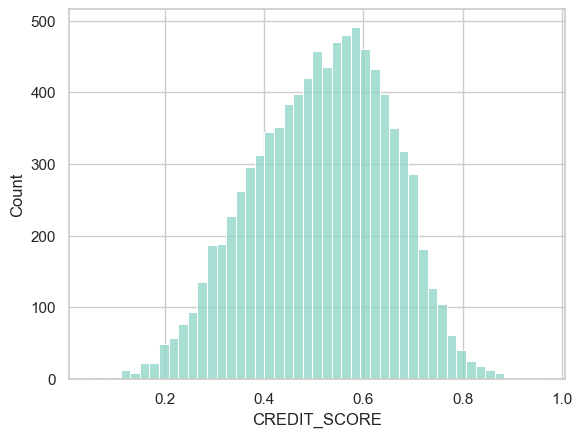

In [244]:
sns.histplot(data=df, x='CREDIT_SCORE')
# sns.histplot(data=df, x='ANNUAL_MILEAGE')

In [245]:
print(df['CREDIT_SCORE'].mean())
print(df['CREDIT_SCORE'].median())

0.515812809602791
0.5250327586154788


<Axes: xlabel='ANNUAL_MILEAGE', ylabel='Count'>

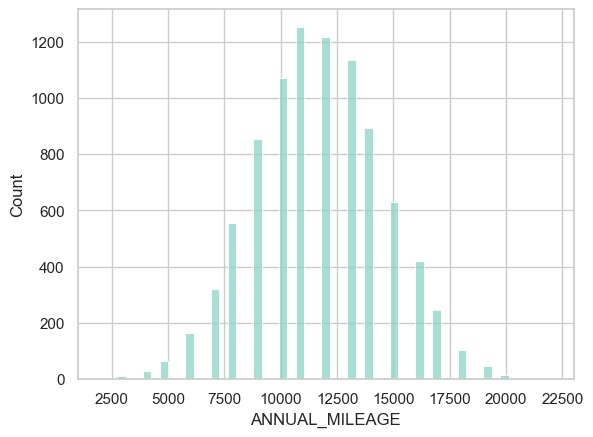

In [246]:
sns.histplot(data=df, x='ANNUAL_MILEAGE')

In [247]:
print(df['ANNUAL_MILEAGE'].mean())
print(df['ANNUAL_MILEAGE'].median())
print(df['ANNUAL_MILEAGE'].mode()[0])


11697.003206900365
12000.0
11000.0


In [248]:
# Outcome

df['OUTCOME'].value_counts()

# mild imbalance

OUTCOME
0.0    6867
1.0    3133
Name: count, dtype: int64

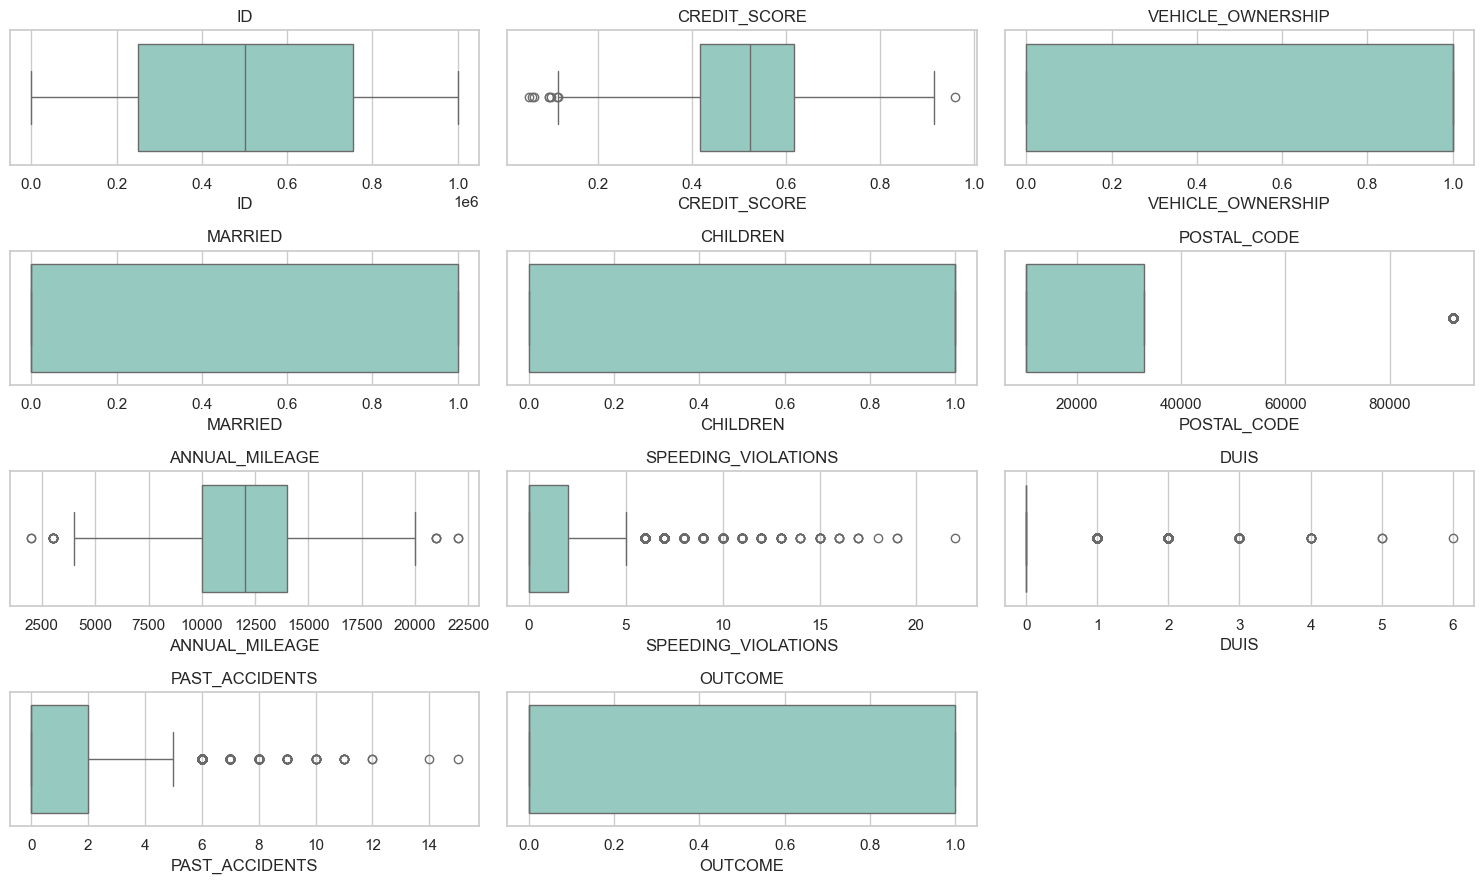

In [249]:
# Numerical Features
num_feature = [fea for fea in df.describe().columns]
num_feature

plt.figure(figsize=(15, 9), facecolor='white')
sns.set(style='whitegrid', palette='Set3')
plotnumber = 1
    
for feature in num_feature:
    ax = plt.subplot(4,3, plotnumber)
    sns.boxplot(x=feature, data=df);
    plt.title(feature, fontsize=12)
    plt.tight_layout()
    plotnumber += 1

In [250]:
df.duplicated().sum()

0

## Data Splitting

In [251]:
# Define X and y
X = df.drop(columns=['OUTCOME','ID'])
y = df['OUTCOME']

In [252]:
# Split
X_train, X_test, y_train, y_test = train_test_split(
    X, 
    y,
    test_size=0.2,
    random_state=0,
    stratify=y
)

## Preprocessing

Impute
- Median:
    - 'CREDIT_SCORE'
    - 'ANNUAL_MILEAGE'

Encode:
- Ordinal Encoder:
    - 'AGE' 
    - 'DRIVING_EXPERIENCE'
    - 'EDUCATION'
    - 'INCOME'
- One Hot Encoder:
    - 'GENDER'
    - 'RACE'
    - 'VEHICLE_YEAR'
    - 'VEHICLE_TYPE'

Scaler:
- MinMax
- Standard
- Robust

In [253]:
# df.describe(include='object')

In [254]:
df['AGE'].unique()

array(['65+', '16-25', '26-39', '40-64'], dtype=object)

In [255]:
X.columns

Index(['AGE', 'GENDER', 'RACE', 'DRIVING_EXPERIENCE', 'EDUCATION', 'INCOME',
       'CREDIT_SCORE', 'VEHICLE_OWNERSHIP', 'VEHICLE_YEAR', 'MARRIED',
       'CHILDREN', 'POSTAL_CODE', 'ANNUAL_MILEAGE', 'VEHICLE_TYPE',
       'SPEEDING_VIOLATIONS', 'DUIS', 'PAST_ACCIDENTS'],
      dtype='object')

In [256]:
# ordinal mapping
ordinal_mapping = [
    {'col':'AGE', 'mapping':{'16-25':20, '26-39':33, '40-64':47, '65+':70, None:0}},
    {'col':'DRIVING_EXPERIENCE', 'mapping':{'0-9y':5, '10-19y':15, '20-29y':25 , '30y+':35, None:0}},
    {'col':'EDUCATION', 'mapping':{'high school':12, 'university':16, 'none':0, None:0}},
    {'col':'INCOME', 'mapping':{'poverty':1, 'working class':2, 'middle class':3, 'upper class':4, None:0}} 
] 

In [257]:
# transformer 1

transformer1 = ColumnTransformer([
    ('imp_median', SimpleImputer(strategy='median'), ['CREDIT_SCORE','ANNUAL_MILEAGE']),
    ('ordinal', OrdinalEncoder(cols=['AGE','DRIVING_EXPERIENCE','EDUCATION','INCOME'], mapping=ordinal_mapping), ['AGE','DRIVING_EXPERIENCE','EDUCATION','INCOME']),
    ('onehot', OneHotEncoder(drop='first'), ['GENDER', 'RACE', 'VEHICLE_YEAR','VEHICLE_TYPE']),
], remainder='passthrough')

In [258]:
# transformer 2

# transformer2 = ColumnTransformer([
#     ('imp_iterative', IterativeImputer(), ['CREDIT_SCORE','ANNUAL_MILEAGE']),
#     ('ordinal', OrdinalEncoder(cols=['AGE','DRIVING_EXPERIENCE','EDUCATION','INCOME'], mapping=ordinal_mapping), ['AGE','DRIVING_EXPERIENCE','EDUCATION','INCOME']),
#     ('onehot', OneHotEncoder(drop='first'), ['GENDER', 'RACE', 'VEHICLE_YEAR','VEHICLE_TYPE']),
# ], remainder='passthrough')

In [259]:
# transformer 3

transformer3 = ColumnTransformer([
    ('imp_iterative', IterativeImputer(), ['CREDIT_SCORE','ANNUAL_MILEAGE']),
    ('onehot', OneHotEncoder(drop='first'), ['GENDER', 'RACE', 'VEHICLE_YEAR','VEHICLE_TYPE','AGE','DRIVING_EXPERIENCE','EDUCATION','INCOME']),
], remainder='passthrough')

In [260]:
# transformer 4

# ordinal_iterative = Pipeline([
#     ('ordinal', OrdinalEncoder(cols=['AGE','DRIVING_EXPERIENCE','EDUCATION','INCOME'], mapping=ordinal_mapping)),
#     ('imp_iterative', IterativeImputer())
# ])

# transformer4 = ColumnTransformer([
#     ('ordinal', ordinal_iterative, ['AGE','DRIVING_EXPERIENCE','EDUCATION','INCOME', 'CREDIT_SCORE','ANNUAL_MILEAGE']),
#     ('onehot', OneHotEncoder(drop='first'), ['GENDER', 'RACE', 'VEHICLE_YEAR','VEHICLE_TYPE']),
# ], remainder='passthrough')

In [261]:
# transformer4

ColumnTransformer(remainder='passthrough',
                  transformers=[('ordinal',
                                 Pipeline(steps=[('ordinal',
                                                  OrdinalEncoder(cols=['AGE',
                                                                       'DRIVING_EXPERIENCE',
                                                                       'EDUCATION',
                                                                       'INCOME'],
                                                                 mapping=[{'col': 'AGE',
                                                                           'data_type': dtype('O'),
                                                                           'mapping': 16-25    20
26-39    33
40-64    47
65+      70
None      0
dtype: int64},
                                                                          {'col': 'DRIVING_EXPERIENCE',
                                                                           'data_type': dtype('O'),
                                                                           'mapping': 0-9y       5
10-19y    15
20-29y    25
30y+      3...
university     16
none            0
None            0
dtype: int64},
                                                                          {'col': 'INCOME',
                                                                           'data_type': dtype('O'),
                                                                           'mapping': poverty          1
working class    2
middle class     3
upper class      4
None             0
dtype: int64}])),
                                                 ('imp_iterative',
                                                  IterativeImputer())]),
                                 ['AGE', 'DRIVING_EXPERIENCE', 'EDUCATION',
                                  'INCOME', 'CREDIT_SCORE', 'ANNUAL_MILEAGE']),
                                ('onehot', OneHotEncoder(drop='first'),
                                 ['GENDER', 'RACE', 'VEHICLE_YEAR',
                                  'VEHICLE_TYPE'])])

In [262]:
# scaler
minmax = MinMaxScaler()
standard = StandardScaler()
robust = RobustScaler()

## Benchmark Model

In [263]:
# Define the models
logreg = LogisticRegression(solver='liblinear',random_state=0)
knn = KNeighborsClassifier(n_neighbors=5)
tree = DecisionTreeClassifier(max_depth=5, random_state=0)

In [264]:
# Pilihan model
models = [logreg, knn, tree]

cv_mean = []
cv_std = []

# Mencari model terbaik berdasarkan f1 score terbesar dan std terkecil
for i in models:
    
    skfold = StratifiedKFold(n_splits = 5)

    model_pipe = Pipeline([
            ('prep', transformer1),
            ('scaler', robust),
            ('model', i)])
    
    model_cv = cross_val_score(
        model_pipe, 
        X_train, 
        y_train, 
        cv = skfold, 
        scoring = 'f1',
        error_score='raise'
        )

    cv_mean.append(model_cv.mean())
    cv_std.append(model_cv.std())

    print(i , model_cv)

LogisticRegression(random_state=0, solver='liblinear') [0.7434555  0.73346693 0.73498965 0.76488396 0.72513369]
KNeighborsClassifier() [0.68972746 0.678      0.66055046 0.69145729 0.67019027]
DecisionTreeClassifier(max_depth=5, random_state=0) [0.74152542 0.69902913 0.72460733 0.7605042  0.72823779]


In [265]:
test =pd.DataFrame({
    'model': models,
    'mean': cv_mean,
    'std': cv_std
}).sort_values(by='mean',ascending=False)
test

,model,mean,std
0,"LogisticRegression(random_state=0, solver='liblinear')",0.740386,0.013559
2,"DecisionTreeClassifier(max_depth=5, random_state=0)",0.730781,0.020257
1,KNeighborsClassifier(),0.677985,0.011697


In [267]:
# test score
models = [knn,logreg,tree]

score = []
model_name = []

for i in models:
    model_pipeline = Pipeline([
        ("preprocessing",transformer1),
        ("modeling",i)
    ])

    #fitting
    model_pipeline.fit(X_train,y_train)

    #model predict
    y_pred_test = model_pipeline.predict(X_test)

    #evaluate 
    f1 = f1_score(y_test,y_pred_test)
    score.append(f1)
    model_name.append(i.__class__.__name__)

In [268]:
scores = pd.DataFrame({
    "model":models,
    "score":score
}).sort_values(by="score",ascending=False)
scores

,model,score
2,"DecisionTreeClassifier(max_depth=5, random_state=0)",0.761983
1,"LogisticRegression(random_state=0, solver='liblinear')",0.742903
0,KNeighborsClassifier(),0.675987


In [269]:
result = test.set_index("model").join(scores.set_index("model"))
result = result.drop(["std"],axis=1)
result["difference"] = result["score"] - result["mean"]
result["difference"] = result["difference"].agg("abs")
result

,mean,score,difference
model,,,
"LogisticRegression(random_state=0, solver='liblinear')",0.740386,0.742903,0.002518
"DecisionTreeClassifier(max_depth=5, random_state=0)",0.730781,0.761983,0.031203
KNeighborsClassifier(),0.677985,0.675987,0.001998


## Hyperparameter Tuning (D3) DEMO

In [270]:
from sklearn.model_selection import GridSearchCV, RandomizedSearchCV

### Grid Search

In [271]:
# len(X_train)

In [272]:
# hyperparameter untuk Decision Tree
hyperparam_space = {
    'algo__max_depth':[2,3,4,5,6,7],                    # 6  
    'algo__min_samples_split':[2,5,10,15,20,50,100],    # 7
    'algo__min_samples_leaf':[2,5,10,15,20,50,100],     # 7
    # 'transformer':[transformer1, transformer4]
}                                                       # 294 kombinasi model dengan hyperparameter berbeda   

# pipeline
pipe_model = Pipeline([
    ('transformer', transformer1),
    # ('scaler', robust),
    ('algo', tree)                  # benchmark model terpilih
])

# Define Grid Search
gridsearch = GridSearchCV(
    estimator=pipe_model,           # model  
    param_grid=hyperparam_space,    # hyperparameter yang mau dituning
    cv=5,                           # jumlah fold  
    scoring='f1',                   # metrics
    n_jobs=-1                       # pakai semua processor
)

In [210]:
# fitting 
gridsearch.fit(X_train, y_train)

/Users/dikjaya/miniconda3/lib/python3.12/site-packages/sklearn/compose/_column_transformer.py:1624: FutureWarning: 
The format of the columns of the 'remainder' transformer in ColumnTransformer.transformers_ will change in version 1.7 to match the format of the other transformers.
At the moment the remainder columns are stored as indices (of type int). With the same ColumnTransformer configuration, in the future they will be stored as column names (of type str).
To use the new behavior now and suppress this warning, use ColumnTransformer(force_int_remainder_cols=False).

  warnings.warn(


GridSearchCV(cv=5,
             estimator=Pipeline(steps=[('transformer',
                                        ColumnTransformer(remainder='passthrough',
                                                          transformers=[('imp_median',
                                                                         SimpleImputer(strategy='median'),
                                                                         ['CREDIT_SCORE',
                                                                          'ANNUAL_MILEAGE']),
                                                                        ('ordinal',
                                                                         OrdinalEncoder(cols=['AGE',
                                                                                              'DRIVING_EXPERIENCE',
                                                                                              'EDUCATION',
                                                                                              'INCOME'],
                                                                                        mapping=[{'col': 'AGE',
                                                                                                  'data_type': dtype('O'),
                                                                                                  'mapping': 16-25    20
26-39    33
40-...
                                                                          'DRIVING_EXPERIENCE',
                                                                          'EDUCATION',
                                                                          'INCOME']),
                                                                        ('onehot',
                                                                         OneHotEncoder(drop='first'),
                                                                         ['GENDER',
                                                                          'RACE',
                                                                          'VEHICLE_YEAR',
                                                                          'VEHICLE_TYPE'])])),
                                       ('algo',
                                        DecisionTreeClassifier(max_depth=5,
                                                               random_state=0))]),
             n_jobs=-1,
             param_grid={'algo__max_depth': [2, 3, 4, 5, 6, 7],
                         'algo__min_samples_leaf': [2, 5, 10, 15, 20, 50, 100],
                         'algo__min_samples_split': [2, 5, 10, 15, 20, 50,
                                                     100]},
             scoring='f1')

In [211]:
df

,ID,AGE,GENDER,RACE,DRIVING_EXPERIENCE,EDUCATION,INCOME,CREDIT_SCORE,VEHICLE_OWNERSHIP,VEHICLE_YEAR,MARRIED,CHILDREN,POSTAL_CODE,ANNUAL_MILEAGE,VEHICLE_TYPE,SPEEDING_VIOLATIONS,DUIS,PAST_ACCIDENTS,OUTCOME
0,569520,65+,female,majority,0-9y,high school,upper class,0.629027,1.0,after 2015,0.0,1.0,10238,12000.0,sedan,0,0,0,0.0
1,750365,16-25,male,majority,0-9y,none,poverty,0.357757,0.0,before 2015,0.0,0.0,10238,16000.0,sedan,0,0,0,1.0
2,199901,16-25,female,majority,0-9y,high school,working class,0.493146,1.0,before 2015,0.0,0.0,10238,11000.0,sedan,0,0,0,0.0
3,478866,16-25,male,majority,0-9y,university,working class,0.206013,1.0,before 2015,0.0,1.0,32765,11000.0,sedan,0,0,0,0.0
4,731664,26-39,male,majority,10-19y,none,working class,0.388366,1.0,before 2015,0.0,0.0,32765,12000.0,sedan,2,0,1,1.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9995,323164,26-39,female,majority,10-19y,university,upper class,0.582787,1.0,before 2015,0.0,0.0,10238,16000.0,sedan,0,0,1,0.0
9996,910346,26-39,female,majority,10-19y,none,middle class,0.522231,1.0,after 2015,0.0,1.0,32765,NaN,sedan,1,0,0,0.0
9997,468409,26-39,male,majority,0-9y,high school,middle class,0.470940,1.0,before 2015,0.0,1.0,10238,14000.0,sedan,0,0,0,0.0
9998,903459,26-39,female,majority,10-19y,high school,poverty,0.364185,0.0,before 2015,0.0,1.0,10238,13000.0,sedan,2,0,1,1.0


In [212]:
# score f1 terbaik
gridsearch.best_score_

0.7485068943487709

In [213]:
# hyperparameter terbaik
gridsearch.best_params_

{'algo__max_depth': 6,
 'algo__min_samples_leaf': 20,
 'algo__min_samples_split': 50}

In [214]:
# model terbaik
gridsearch.best_estimator_

Pipeline(steps=[('transformer',
                 ColumnTransformer(remainder='passthrough',
                                   transformers=[('imp_median',
                                                  SimpleImputer(strategy='median'),
                                                  ['CREDIT_SCORE',
                                                   'ANNUAL_MILEAGE']),
                                                 ('ordinal',
                                                  OrdinalEncoder(cols=['AGE',
                                                                       'DRIVING_EXPERIENCE',
                                                                       'EDUCATION',
                                                                       'INCOME'],
                                                                 mapping=[{'col': 'AGE',
                                                                           'data_type': dtype('O'),
                                                                           'mapping': 16-25    20
26-39    33
40-64    47
65+      70
None      0
dtype: int64},
                                                                          {...
                                                                          {'col': 'INCOME',
                                                                           'data_type': dtype('O'),
                                                                           'mapping': poverty          1
working class    2
middle class     3
upper class      4
None             0
dtype: int64}]),
                                                  ['AGE', 'DRIVING_EXPERIENCE',
                                                   'EDUCATION', 'INCOME']),
                                                 ('onehot',
                                                  OneHotEncoder(drop='first'),
                                                  ['GENDER', 'RACE',
                                                   'VEHICLE_YEAR',
                                                   'VEHICLE_TYPE'])])),
                ('algo',
                 DecisionTreeClassifier(max_depth=6, min_samples_leaf=20,
                                        min_samples_split=50,
                                        random_state=0))])

In [206]:
# score f1 pada tiap kombinasi hyperparameter
# cv_output = pd.DataFrame(gridsearch.cv_results_).sort_values('mean_test_score', ascending=False)
# cv_output.head()

### Randomized Search

In [273]:
# hyperparameter untuk Decision Tree
hyperparam_space = {
    'algo__max_depth':range(2,20,1),            # 19                   
    'algo__min_samples_split':range(2,100,1),   # 99        
    'algo__min_samples_leaf':range(1,100,1),    # 100         
    'scaler':[minmax, standard, robust],        # 3
    'transformer':[transformer1, transformer4]  # 2
}                                                         

# pipeline
pipe_model = Pipeline([
    ('transformer',transformer4),
    ('scaler', robust),
    ('algo', tree)          # benchmark model terpilih
])

In [274]:
# Define Randomized Search

random_search = RandomizedSearchCV(
    estimator=pipe_model,
    param_distributions=hyperparam_space,
    cv=5,
    scoring='f1',
    n_jobs=-1,
    random_state=10,
    n_iter=100                 # jumlah kombinasi hyperparameter yang akan dihasilkan
)

In [275]:
# fitting 
random_search.fit(X_train, y_train)

/Users/dikjaya/miniconda3/lib/python3.12/site-packages/sklearn/compose/_column_transformer.py:1624: FutureWarning: 
The format of the columns of the 'remainder' transformer in ColumnTransformer.transformers_ will change in version 1.7 to match the format of the other transformers.
At the moment the remainder columns are stored as indices (of type int). With the same ColumnTransformer configuration, in the future they will be stored as column names (of type str).
To use the new behavior now and suppress this warning, use ColumnTransformer(force_int_remainder_cols=False).

  warnings.warn(


RandomizedSearchCV(cv=5,
                   estimator=Pipeline(steps=[('transformer',
                                              ColumnTransformer(remainder='passthrough',
                                                                transformers=[('ordinal',
                                                                               Pipeline(steps=[('ordinal',
                                                                                                OrdinalEncoder(cols=['AGE',
                                                                                                                     'DRIVING_EXPERIENCE',
                                                                                                                     'EDUCATION',
                                                                                                                     'INCOME'],
                                                                                                               mapping=[{'col': 'AGE',
                                                                                                                         'data_type': dtype('O'),
                                                                                                                         'mapping': 16-25    20
26-39    33
40-64    47
65+      70
None      0
dtype: int64},
                                                                                                                        {'col': 'DRIVING_EXPERI...
                                                                                                                                  {'col': 'INCOME',
                                                                                                                                   'data_type': dtype('O'),
                                                                                                                                   'mapping': poverty          1
working class    2
middle class     3
upper class      4
None             0
dtype: int64}])),
                                                                                                         ('imp_iterative',
                                                                                                          IterativeImputer())]),
                                                                                         ['AGE',
                                                                                          'DRIVING_EXPERIENCE',
                                                                                          'EDUCATION',
                                                                                          'INCOME',
                                                                                          'CREDIT_SCORE',
                                                                                          'ANNUAL_MILEAGE']),
                                                                                        ('onehot',
                                                                                         OneHotEncoder(drop='first'),
                                                                                         ['GENDER',
                                                                                          'RACE',
                                                                                          'VEHICLE_YEAR',
                                                                                          'VEHICLE_TYPE'])])]},
                   random_state=10, scoring='f1')

In [276]:
# score f1 terbaik
random_search.best_score_

0.753426427795238

In [277]:
# hyperparameter terbaik
random_search.best_params_

{'transformer': ColumnTransformer(remainder='passthrough',
                   transformers=[('ordinal',
                                  Pipeline(steps=[('ordinal',
                                                   OrdinalEncoder(cols=['AGE',
                                                                        'DRIVING_EXPERIENCE',
                                                                        'EDUCATION',
                                                                        'INCOME'],
                                                                  mapping=[{'col': 'AGE',
                                                                            'data_type': dtype('O'),
                                                                            'mapping': 16-25    20
 26-39    33
 40-64    47
 65+      70
 None      0
 dtype: int64},
                                                                           {'col': 'DRIVING_EXPERIENCE',
                              

In [278]:
# model terbaik
random_search.best_estimator_

Pipeline(steps=[('transformer',
                 ColumnTransformer(remainder='passthrough',
                                   transformers=[('ordinal',
                                                  Pipeline(steps=[('ordinal',
                                                                   OrdinalEncoder(cols=['AGE',
                                                                                        'DRIVING_EXPERIENCE',
                                                                                        'EDUCATION',
                                                                                        'INCOME'],
                                                                                  mapping=[{'col': 'AGE',
                                                                                            'data_type': dtype('O'),
                                                                                            'mapping': 16-25    20
26-39    33
40-64    47
65+      70
None      0
dtype: int64},
                                                                                           {'col': 'DRIVING_EXPERIENCE',
                                                                                            'data_type': dtype('O'),
                                                                                            'mapp...
dtype: int64}])),
                                                                  ('imp_iterative',
                                                                   IterativeImputer())]),
                                                  ['AGE', 'DRIVING_EXPERIENCE',
                                                   'EDUCATION', 'INCOME',
                                                   'CREDIT_SCORE',
                                                   'ANNUAL_MILEAGE']),
                                                 ('onehot',
                                                  OneHotEncoder(drop='first'),
                                                  ['GENDER', 'RACE',
                                                   'VEHICLE_YEAR',
                                                   'VEHICLE_TYPE'])])),
                ('scaler', RobustScaler()),
                ('algo',
                 DecisionTreeClassifier(max_depth=7, min_samples_leaf=33,
                                        min_samples_split=27,
                                        random_state=0))])

In [279]:
X_train

,AGE,GENDER,RACE,DRIVING_EXPERIENCE,EDUCATION,INCOME,CREDIT_SCORE,VEHICLE_OWNERSHIP,VEHICLE_YEAR,MARRIED,CHILDREN,POSTAL_CODE,ANNUAL_MILEAGE,VEHICLE_TYPE,SPEEDING_VIOLATIONS,DUIS,PAST_ACCIDENTS
4612,65+,male,majority,30y+,university,upper class,NaN,1.0,after 2015,0.0,1.0,10238,8000.0,sedan,6,1,5
3947,40-64,male,majority,0-9y,university,middle class,0.566679,0.0,before 2015,0.0,0.0,32765,12000.0,sedan,0,0,0
1429,40-64,female,majority,20-29y,university,upper class,0.582356,1.0,after 2015,1.0,1.0,10238,12000.0,sedan,0,0,0
9434,26-39,female,majority,10-19y,university,upper class,0.437535,0.0,before 2015,1.0,1.0,10238,9000.0,sedan,1,0,1
315,40-64,female,minority,20-29y,high school,middle class,0.586063,0.0,before 2015,0.0,1.0,32765,13000.0,sports car,2,1,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1650,65+,male,majority,10-19y,university,upper class,0.584608,0.0,before 2015,1.0,1.0,10238,13000.0,sedan,0,1,2
8803,26-39,male,majority,10-19y,high school,middle class,0.514461,1.0,before 2015,1.0,1.0,10238,13000.0,sports car,0,1,0
4394,16-25,male,majority,0-9y,high school,working class,0.382824,1.0,after 2015,0.0,0.0,10238,16000.0,sedan,0,0,0
5729,16-25,male,majority,0-9y,university,poverty,0.485069,0.0,before 2015,0.0,0.0,32765,NaN,sedan,0,0,0


In [201]:
# score f1 pada tiap kombinasi hyperparameter
# cv_output = pd.DataFrame(random_search.cv_results_).sort_values('mean_test_score', ascending=False)
# cv_output.head()

Performa model di Train Set
- Benchmark model: 0.73
- Hyperparameter Tuning (GridSearchCV): 0.74
- Hyperparameter Tuning (RandomizedSearchCV): 0.75


## Predict to Test Set

- Melakukan prediksi pada test set dengan menggunakan model terbaik dan hyperparameter terbaik.
- Membandingkan performa model sebelum tuning dan setelah tuning.


### Befor Tuning

In [224]:
# define model
model = DecisionTreeClassifier(max_depth=5)
pipe_model = Pipeline([
    ('transformer',transformer1),
    # ('scaler', robust),
    ('algo', model)          # benchmark model terpilih
])

# fitting
pipe_model.fit(X_train, y_train)

# predict
y_pred = pipe_model.predict(X_test)
f1_score(y_test, y_pred)


0.7619834710743801

### After Tuning 

In [225]:
# menggunakan model terbaik hasil gridsearch
model = gridsearch.best_estimator_
model.fit(X_train, y_train)

y_pred = model.predict(X_test)
f1_score(y_test, y_pred)

0.7702265372168284

In [226]:
# menggunakan model terbaik hasil random_search
model = random_search.best_estimator_
model.fit(X_train, y_train)

y_pred = model.predict(X_test)
f1_score(y_test, y_pred)

0.7698476343223737

## Summary

Performa Decision Tree pada Train Set
- Benchmark: 0.73
- Grid Search: 0.74
- Random Search: 0.75

Performa Decision Tree pada Test Set
- Benchmark: 0.761
- Grid Search: 0.770
- Random Search: 0.764

---
---

In [60]:
# model_pipe = Pipeline([
#         ('prep', transformer1), 
#         ('scaler', robust), 
#         ('model', logreg)])

# model_pipe.fit(X_train, y_train)

# model_pipe['model'].coef_

In [61]:
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

         0.0       0.90      0.89      0.90      1373
         1.0       0.77      0.78      0.77       627

    accuracy                           0.86      2000
   macro avg       0.83      0.84      0.84      2000
weighted avg       0.86      0.86      0.86      2000



In [62]:
# model.predict_proba(X_test)

In [63]:
plt.figure(figsize=(14,8))

# predict probabilities
yhat = model.predict_proba(X_test)

# keep probabilities for the positive outcome only
yhat = yhat[:, 1]

# calculate pr-curve
precision, recall, thresholds = precision_recall_curve(y_test, yhat)

<Figure size 1400x800 with 0 Axes>

In [64]:
yhat

array([0.        , 0.78767123, 0.90909091, ..., 0.22123894, 0.95135135,
       0.99086758])

In [65]:
precision.shape

(75,)

In [66]:
recall.shape

(75,)

In [67]:
thresholds

array([0.        , 0.00862069, 0.01538462, 0.02020202, 0.02083333,
       0.02380952, 0.02777778, 0.03030303, 0.03773585, 0.05      ,
       0.06122449, 0.06896552, 0.07526882, 0.08695652, 0.09090909,
       0.11320755, 0.11764706, 0.12121212, 0.12797619, 0.15151515,
       0.16923077, 0.17460317, 0.1754386 , 0.17808219, 0.18      ,
       0.22123894, 0.22807018, 0.26470588, 0.26829268, 0.27083333,
       0.27272727, 0.27647059, 0.29787234, 0.34146341, 0.36363636,
       0.4047619 , 0.41176471, 0.45      , 0.46258503, 0.46710526,
       0.49350649, 0.50588235, 0.54761905, 0.54891304, 0.57317073,
       0.59183673, 0.62857143, 0.65517241, 0.65789474, 0.66176471,
       0.66666667, 0.67592593, 0.67647059, 0.68518519, 0.73214286,
       0.73529412, 0.73684211, 0.77142857, 0.78767123, 0.79545455,
       0.80434783, 0.80952381, 0.83333333, 0.83928571, 0.85      ,
       0.875     , 0.90243902, 0.90909091, 0.94285714, 0.95135135,
       0.95348837, 0.96052632, 0.99086758, 1.        ])

In [68]:
# precision_recall_curve(y_test, yhat)

In [69]:
# precision_recall_curve(y_test, y_pred)

In [70]:
pd.DataFrame({
    'precision': precision,
    'recall': recall,
    'thresholds': list(thresholds) + [0]
}).sort_values('precision', ascending=False)

,precision,recall,thresholds
74,1.000000,0.000000,0.000000
73,1.000000,0.022329,1.000000
70,0.961905,0.161085,0.953488
71,0.958333,0.146730,0.960526
72,0.948718,0.118022,0.990868
...,...,...,...
4,0.428276,0.990431,0.020833
3,0.423313,0.990431,0.020202
2,0.418011,0.992026,0.015385
1,0.402589,0.992026,0.008621


''

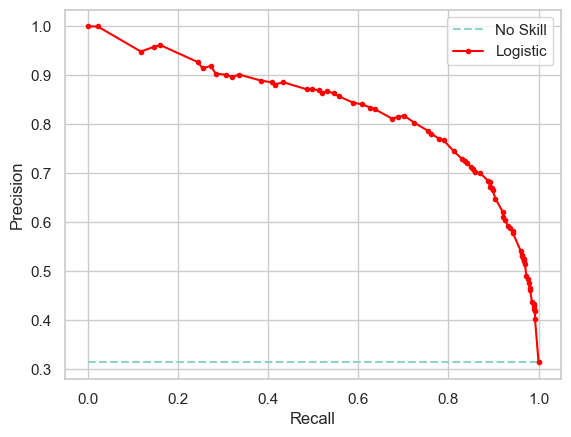

In [71]:
# plot the roc curve for the model
no_skill = len(y_test[y_test==1]) / len(y_test)
plt.plot([0,1], [no_skill,no_skill], linestyle='--', label='No Skill')
plt.plot(recall, precision, marker='.', label='Logistic', color='r')

# axis labels
plt.xlabel('Recall')
plt.ylabel('Precision')
plt.legend()
;

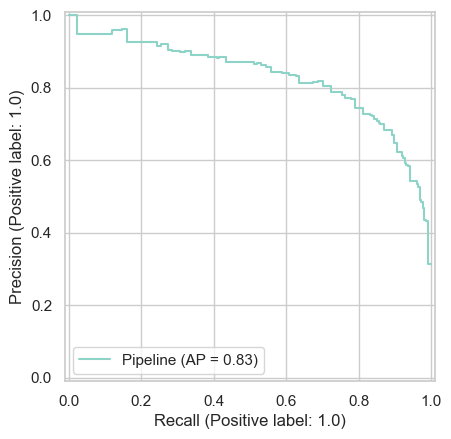

In [72]:
# PR curve
from sklearn.metrics import PrecisionRecallDisplay
# plot_precision_recall_curve(model, X_test, y_test);
PrecisionRecallDisplay.from_estimator(model, X_test, y_test);

In [73]:
# PR curve
# plot_precision_recall_curve(model, X_test, y_test);

In [74]:
confusion_matrix(y_test, y_pred)

array([[1228,  145],
       [ 139,  488]])

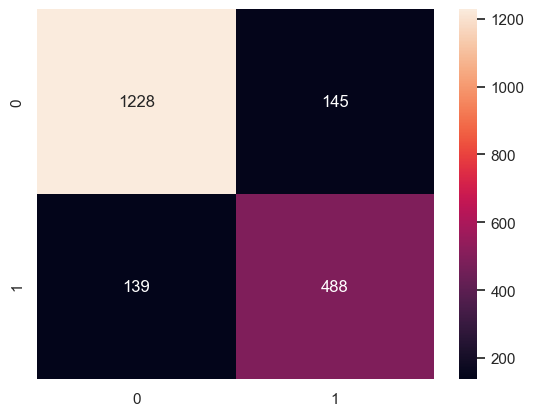

In [75]:
sns.heatmap(confusion_matrix(y_test, y_pred), annot=True, fmt='g');

- TP: 488 (diprediksi melakukan claim, dan aktualnya juga melakukan claim)
- TN: 1228 (diprediksi tidak melakukan claim, dan aktualnya juga tidak melakukan claim)
- FP: 145 (diprediksi melakukan claim, tapi aktualnya TIDAK melakukan claim)
- FN: 139 (diprediksi TIDAK melakukan claim, tapi aktualnya melakukan claim)

FP cost: Kita mengira orang tersebut akan melakukan klaim yg mana akan membuat perusahaan mengeluarkan uang, padahal ternyata tidak. Jadi kita kehilangan calon nasabah.

FN cost: Kita mengira orang tersebut TIDAK akan melakukan klaim, yg artinya TIDAK akan membuat perusahaan mengeluarkan uang, padahal ternyata tidak.

In [76]:
# ?plot_tree

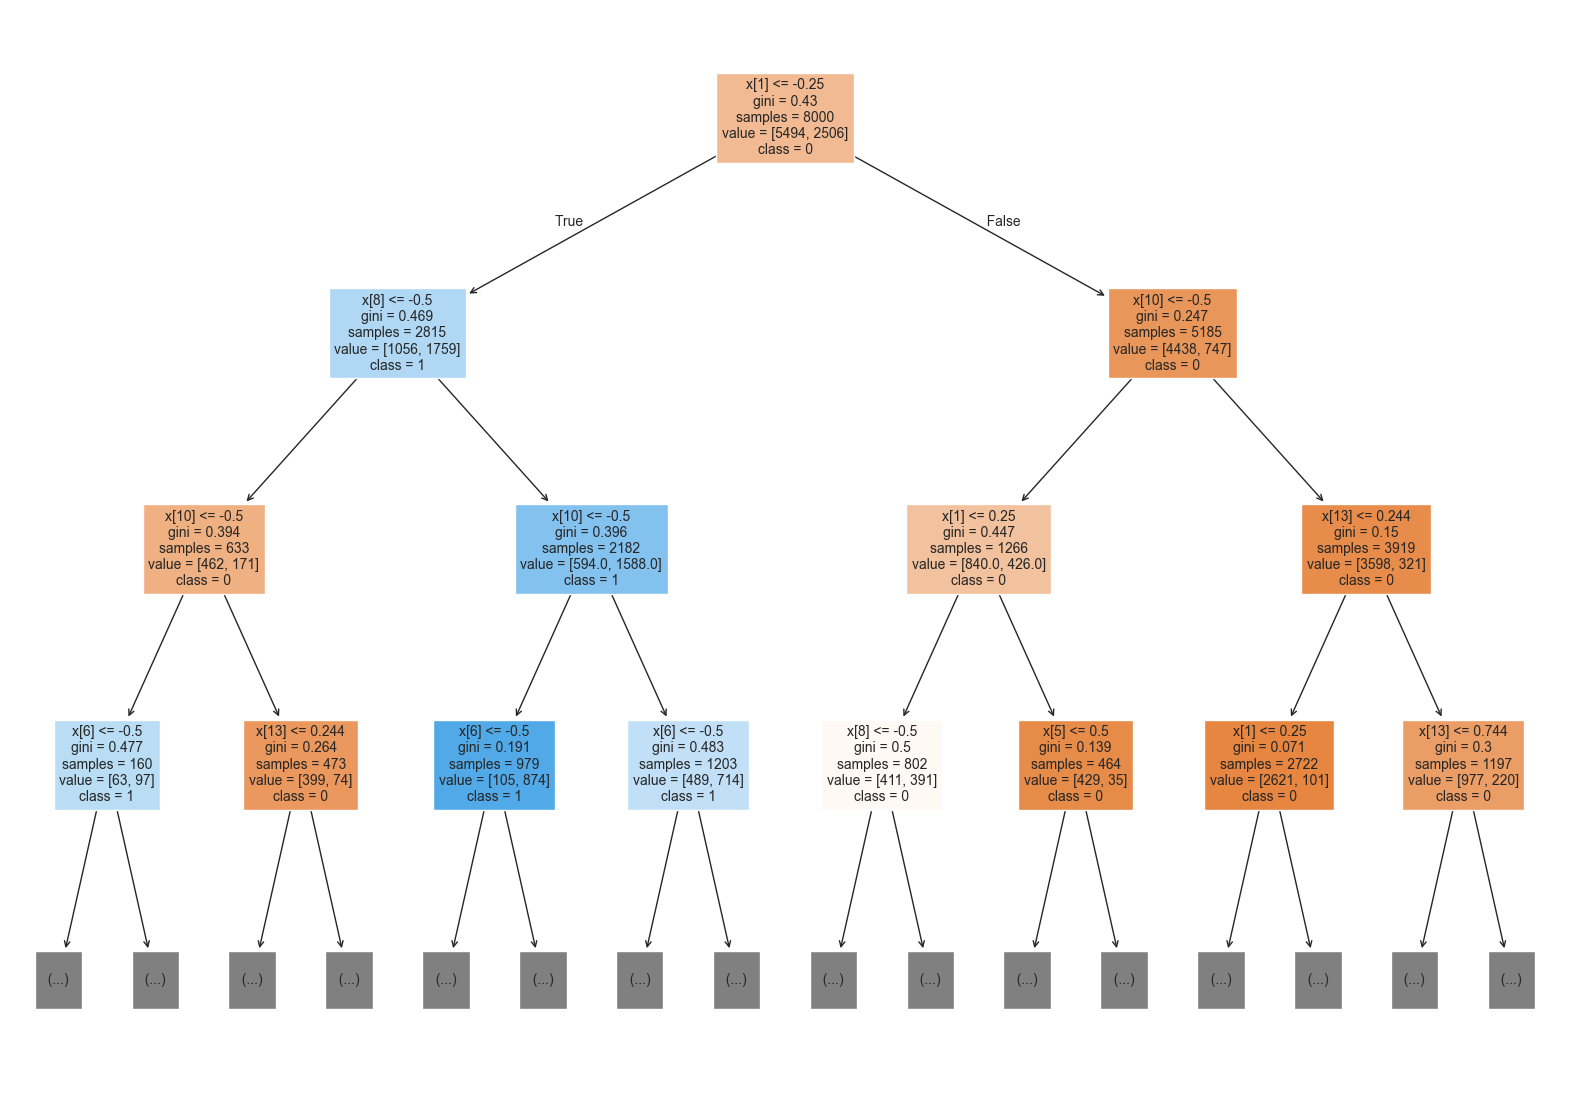

In [77]:
plt.figure(figsize = (20,14))
plot_tree(model['algo'], filled = True, class_names = ['0','1'], fontsize=10, max_depth=3 )
plt.show()

In [78]:
transformer1.fit_transform(X_train)

array([[5.24045331e-01, 8.00000000e+03, 7.00000000e+01, ...,
        6.00000000e+00, 1.00000000e+00, 5.00000000e+00],
       [5.66678699e-01, 1.20000000e+04, 4.70000000e+01, ...,
        0.00000000e+00, 0.00000000e+00, 0.00000000e+00],
       [5.82355999e-01, 1.20000000e+04, 4.70000000e+01, ...,
        0.00000000e+00, 0.00000000e+00, 0.00000000e+00],
       ...,
       [3.82823591e-01, 1.60000000e+04, 2.00000000e+01, ...,
        0.00000000e+00, 0.00000000e+00, 0.00000000e+00],
       [4.85068916e-01, 1.20000000e+04, 2.00000000e+01, ...,
        0.00000000e+00, 0.00000000e+00, 0.00000000e+00],
       [6.97389999e-01, 8.00000000e+03, 7.00000000e+01, ...,
        3.00000000e+00, 3.00000000e+00, 0.00000000e+00]])

In [192]:
transformer1.transformers_

[('imp_median',
  SimpleImputer(strategy='median'),
  ['CREDIT_SCORE', 'ANNUAL_MILEAGE']),
 ('ordinal',
  OrdinalEncoder(cols=['AGE', 'DRIVING_EXPERIENCE', 'EDUCATION', 'INCOME'],
                 mapping=[{'col': 'AGE', 'data_type': dtype('O'),
                           'mapping': 16-25    20
  26-39    33
  40-64    47
  65+      70
  None      0
  dtype: int64},
                          {'col': 'DRIVING_EXPERIENCE', 'data_type': dtype('O'),
                           'mapping': 0-9y       5
  10-19y    15
  20-29y    25
  30y+      35
  None       0
  dtype: int64},
                          {'col': 'EDUCATION', 'data_type': dtype('O'),
                           'mapping': high school    12
  university     16
  none            0
  None            0
  dtype: int64},
                          {'col': 'INCOME', 'data_type': dtype('O'),
                           'mapping': poverty          1
  working class    2
  middle class     3
  upper class      4
  None             0
  dtype

In [183]:
f_imp = transformer1.transformers[0][2]
f_imp

['CREDIT_SCORE', 'ANNUAL_MILEAGE']

In [182]:
f_ordinal = transformer1.transformers[1][1].cols
f_ordinal

['AGE', 'DRIVING_EXPERIENCE', 'EDUCATION', 'INCOME']

In [181]:
f_onehot = transformer1.named_transformers_['onehot'].get_feature_names_out()
f_onehot

array(['GENDER_male', 'RACE_minority', 'VEHICLE_YEAR_before 2015',
       'VEHICLE_TYPE_sports car'], dtype=object)

In [179]:
transformer1.transformers_[2][1].get_feature_names_out()

array(['GENDER_male', 'RACE_minority', 'VEHICLE_YEAR_before 2015',
       'VEHICLE_TYPE_sports car'], dtype=object)

In [188]:
# f_remain = df.columns[transformer2.transformers_[3][2]]
f_remain = transformer1.transformers_[3][1].get_feature_names_out()
f_remain

array(['VEHICLE_OWNERSHIP', 'MARRIED', 'CHILDREN', 'POSTAL_CODE',
       'SPEEDING_VIOLATIONS', 'DUIS', 'PAST_ACCIDENTS'], dtype=object)

In [189]:
feat = list(f_imp) + list(f_ordinal) + list(f_onehot) + list(f_remain)
feat

['CREDIT_SCORE',
 'ANNUAL_MILEAGE',
 'AGE',
 'DRIVING_EXPERIENCE',
 'EDUCATION',
 'INCOME',
 'GENDER_male',
 'RACE_minority',
 'VEHICLE_YEAR_before 2015',
 'VEHICLE_TYPE_sports car',
 'VEHICLE_OWNERSHIP',
 'MARRIED',
 'CHILDREN',
 'POSTAL_CODE',
 'SPEEDING_VIOLATIONS',
 'DUIS',
 'PAST_ACCIDENTS']

In [190]:
pd.DataFrame({
    'feat': feat,
    'imp': model['algo'].feature_importances_
}).sort_values('imp')

,feat,imp
16,PAST_ACCIDENTS,0.000000
9,VEHICLE_TYPE_sports car,0.000000
7,RACE_minority,0.000000
14,SPEEDING_VIOLATIONS,0.000090
15,DUIS,0.000138
12,CHILDREN,0.000849
3,DRIVING_EXPERIENCE,0.001476
0,CREDIT_SCORE,0.002123
2,AGE,0.002161
4,EDUCATION,0.005324
